Dataset Shape: (1436, 11)

Columns: ['Price', 'Age_08_04', 'KM', 'Fuel_Type', 'HP', 'Automatic', 'cc', 'Doors', 'Cylinders', 'Gears', 'Weight']

--- Summary Statistics ---
              Price    Age_08_04             KM           HP    Automatic  \
count   1436.000000  1436.000000    1436.000000  1436.000000  1436.000000   
mean   10730.824513    55.947075   68533.259749   101.502089     0.055710   
std     3626.964585    18.599988   37506.448872    14.981080     0.229441   
min     4350.000000     1.000000       1.000000    69.000000     0.000000   
25%     8450.000000    44.000000   43000.000000    90.000000     0.000000   
50%     9900.000000    61.000000   63389.500000   110.000000     0.000000   
75%    11950.000000    70.000000   87020.750000   110.000000     0.000000   
max    32500.000000    80.000000  243000.000000   192.000000     1.000000   

                cc        Doors  Cylinders        Gears      Weight  
count   1436.00000  1436.000000     1436.0  1436.000000  1436.00

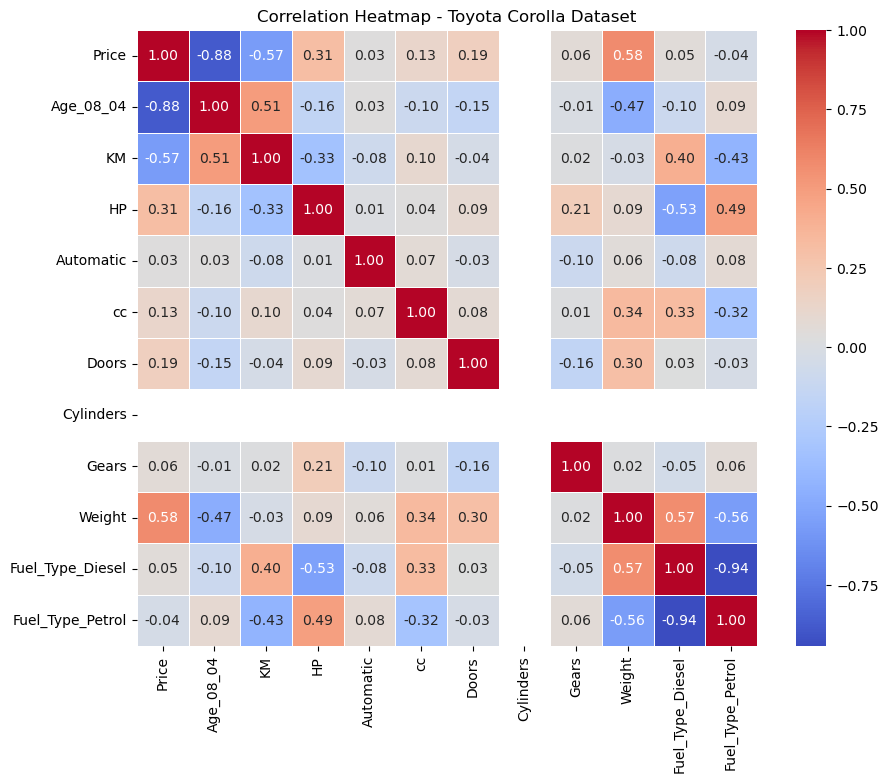

In [1]:
""" MULTIPLE LINEAR REGRESSION """

# Task 1: Exploratory Data Analysis (EDA) & Pre-processing 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Dataset
df = pd.read_csv("ToyotaCorolla - MLR.csv")
print("Dataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())

# 2. Summary Statistics
print("\n--- Summary Statistics ---")
print(df.describe())

# 3. Check Missing Values
print("\nMissing Values:\n", df.isnull().sum())

# 4. Pre-processing: One-hot encode categorical variable 'Fuel_Type'
df_encoded = pd.get_dummies(df, columns=['Fuel_Type'], drop_first=True, dtype=int)

# 5. Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df_encoded.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap - Toyota Corolla Dataset')
plt.show()

In [2]:
# Task 2: Data Splitting (Training & Testing Sets) 
from sklearn.model_selection import train_test_split

X = df_encoded.drop(columns=['Price'])
y = df_encoded['Price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training Set Shape: {X_train.shape}")
print(f"Testing Set Shape: {X_test.shape}")

Training Set Shape: (1148, 11)
Testing Set Shape: (288, 11)


In [3]:
#Task 3: Building Multiple Linear Regression Models (Minimum 3 Models)
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

# Model 1: Full Features
lr_model1 = LinearRegression()
lr_model1.fit(X_train, y_train)

# Model 2: Reduced Features
core_features = ['Age_08_04', 'KM', 'HP', 'Weight', 'cc']
lr_model2 = LinearRegression()
lr_model2.fit(X_train[core_features], y_train)

# Model 3: Polynomial Features
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train[['Age_08_04', 'KM', 'HP', 'Weight']])
X_test_poly = poly.transform(X_test[['Age_08_04', 'KM', 'HP', 'Weight']])

lr_model3 = LinearRegression()
lr_model3.fit(X_train_poly, y_train)

# Interpret coefficients of Model 1
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr_model1.coef_
})
print("\n--- Model 1 Coefficients ---")
print(coefficients)
print(f"Intercept: {lr_model1.intercept_:.2f}")


--- Model 1 Coefficients ---
             Feature   Coefficient
0          Age_08_04 -1.208305e+02
1                 KM -1.623141e-02
2                 HP  1.403948e+01
3          Automatic  1.488309e+02
4                 cc -3.037219e-02
5              Doors -6.031097e+01
6          Cylinders  6.536993e-13
7              Gears  5.516007e+02
8             Weight  2.588496e+01
9   Fuel_Type_Diesel -6.854876e+01
10  Fuel_Type_Petrol  1.370809e+03
Intercept: -14255.39


In [4]:
#Task 4: Model Evaluation
from sklearn.metrics import mean_squared_error, r2_score

y_pred1 = lr_model1.predict(X_test)
y_pred2 = lr_model2.predict(X_test[core_features])
y_pred3 = lr_model3.predict(X_test_poly)

eval_summary = pd.DataFrame({
    'Model': ['Model 1 (Full Features)', 'Model 2 (Reduced Features)', 'Model 3 (Polynomial)'],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred1)),
        np.sqrt(mean_squared_error(y_test, y_pred2)),
        np.sqrt(mean_squared_error(y_test, y_pred3))
    ],
    'R2 Score': [
        r2_score(y_test, y_pred1),
        r2_score(y_test, y_pred2),
        r2_score(y_test, y_pred3)
    ]
})

print("\n--- Model Evaluation Summary ---")
print(eval_summary)


--- Model Evaluation Summary ---
                        Model         RMSE  R2 Score
0     Model 1 (Full Features)  1484.265415  0.834889
1  Model 2 (Reduced Features)  1412.786197  0.850409
2        Model 3 (Polynomial)  1079.543783  0.912656


In [5]:
#Task 5: Applying Ridge and Lasso Regularization
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Ridge Regression (L2)
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)
y_pred_ridge = ridge.predict(X_test_scaled)

# Lasso Regression (L1)
lasso = Lasso(alpha=1.0)
lasso.fit(X_train_scaled, y_train)
y_pred_lasso = lasso.predict(X_test_scaled)

reg_summary = pd.DataFrame({
    'Model': ['Ridge Regression', 'Lasso Regression'],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
        np.sqrt(mean_squared_error(y_test, y_pred_lasso))
    ],
    'R2 Score': [
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_lasso)
    ]
})

print("\n--- Regularization Summary ---")
print(reg_summary)


--- Regularization Summary ---
              Model         RMSE  R2 Score
0  Ridge Regression  1483.557506  0.835046
1  Lasso Regression  1483.235687  0.835118
